# Model 1: Principal Component Analysis (PCA)
**Dataset:** Plant Disease Recognition (Healthy / Powdery / Rust)

**Category:** Dimensionality Reduction

## Model suitability
Each leaf image flattened to 64×64×3 gives 12,288 pixel features, but the dataset has only ~1,300 training images.
Neighbouring pixels are highly correlated, so most features are redundant. PCA finds a small number of
orthogonal directions that keep most of the variance, which makes the downstream classifiers faster and less
prone to overfitting on pixel noise.

## Implementation details
`sklearn.decomposition.PCA`, fitted on the **training set only** (then applied to validation/test, to avoid leakage).
Input = flattened, 0–1 scaled pixels. Downstream check = RBF SVM inside a `Pipeline`.
## Parameter tuning method
Manual tuning, compared against a no-PCA baseline. Three kinds of varieties are tried: (a) fixed `n_components` (50, 100, 150, 200, 300),
(b) variance thresholds (keep 90% and 95% of the variance), and (c) different preprocessing (standardised pixels + PCA, and PCA on the colour histogram).
Selection uses 5-fold cross-validation on the training set.

## Evaluation metric & validation method
PCA is unsupervised, so accuracy does not apply to it directly. It is evaluated by
(1) **variance retained** and (2) **downstream accuracy** of an SVM trained on the reduced features
(5-fold CV on Train, then Validation and Test), plus fit time.

In [1]:
# ---- Configuration (paths are relative to the notebooks/ folder) ----
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
warnings.filterwarnings('ignore')

DATA_ROOT = '../data/raw'      # folder that contains Train/, Validation/ and Test/
SPLITS = {s: os.path.join(DATA_ROOT, s, s) for s in ['Train', 'Validation', 'Test']}  # dataset is nested: Train/Train/...
RESULTS = '../results'
os.makedirs(f'{RESULTS}/eda_visualizations', exist_ok=True)
os.makedirs(f'{RESULTS}/outputs', exist_ok=True)

CLASS_NAMES = sorted(d for d in os.listdir(SPLITS['Train']) if os.path.isdir(os.path.join(SPLITS['Train'], d)))
print('Classes:', CLASS_NAMES)
for s, p in SPLITS.items():
    print(s, {c: len(os.listdir(os.path.join(p, c))) for c in CLASS_NAMES})

Classes: ['Healthy', 'Powdery', 'Rust']
Train {'Healthy': 458, 'Powdery': 430, 'Rust': 434}
Validation {'Healthy': 20, 'Powdery': 20, 'Rust': 20}
Test {'Healthy': 50, 'Powdery': 50, 'Rust': 50}


In [2]:
# Helper: every notebook appends its results to one shared CSV (used later for the group comparison)
def log_result(model, variety, val_acc=None, test_acc=None, notes=''):
    path = f'{RESULTS}/outputs/model_results.csv'
    cols = ['model', 'variety', 'val_accuracy', 'test_accuracy', 'notes']
    df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=cols)
    df = df[~((df['model'] == model) & (df['variety'] == variety))].reset_index(drop=True)
    df.loc[len(df)] = [model, variety, val_acc, test_acc, notes]
    df.to_csv(path, index=False)

In [3]:
# ---- Flat features for classical ML (same preprocessing as the group pipeline) ----
#   pixels    : 64x64x3 image flattened and scaled to 0-1  (12,288 values)
#   histogram : 8x8x8 RGB colour histogram               (512 values)
def hist_feat(img):
    h = cv2.calcHist([img], [0, 1, 2], None, [8, 8, 8], [0, 256] * 3)
    return cv2.normalize(h, h).flatten()

def build_features(split, flat_size=64):
    Xp, Xh, y = [], [], []
    for idx, c in enumerate(CLASS_NAMES):
        folder = os.path.join(SPLITS[split], c)
        for f in sorted(os.listdir(folder)):
            if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            try:
                img = np.array(Image.open(os.path.join(folder, f)).convert('RGB').resize((128, 128)))
            except Exception:
                continue                      # skip unreadable files
            Xh.append(hist_feat(img))
            Xp.append(cv2.resize(img, (flat_size, flat_size)).flatten() / 255.0)
            y.append(idx)
    return np.array(Xp, dtype='float32'), np.array(Xh, dtype='float32'), np.array(y)

CACHE = f'{RESULTS}/outputs/plant_features.npz'      # built once, reused by every notebook
keys = ['Xp_tr', 'Xh_tr', 'y_tr', 'Xp_va', 'Xh_va', 'y_va', 'Xp_te', 'Xh_te', 'y_te']
if os.path.exists(CACHE):
    d = np.load(CACHE)
    Xp_tr, Xh_tr, y_tr, Xp_va, Xh_va, y_va, Xp_te, Xh_te, y_te = [d[k] for k in keys]
else:
    Xp_tr, Xh_tr, y_tr = build_features('Train')
    Xp_va, Xh_va, y_va = build_features('Validation')
    Xp_te, Xh_te, y_te = build_features('Test')
    np.savez_compressed(CACHE, **dict(zip(keys, [Xp_tr, Xh_tr, y_tr, Xp_va, Xh_va, y_va, Xp_te, Xh_te, y_te])))
print('Train', Xp_tr.shape, Xh_tr.shape, '| Val', Xp_va.shape, '| Test', Xp_te.shape)

Train (1322, 12288) (1322, 512) | Val (60, 12288) | Test (150, 12288)


In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import seaborn as sns

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def show_confusion(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(title); plt.tight_layout()
    plt.savefig(f'{RESULTS}/eda_visualizations/{fname}', dpi=200)
    plt.show()

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

N_COMPONENTS = [50, 100, 150, 200, 300]   # fixed-size varieties
BASELINE_CV = True                        # CV of the no-PCA model is slow (10-20 min); set False to skip
rows, pipes = [], {}

def evaluate(name, pipe, Xtr, Xva, Xte, do_cv=True):
    cv_acc = cross_val_score(pipe, Xtr, y_tr, cv=cv, n_jobs=-1).mean() if do_cv else np.nan
    t = time.perf_counter()
    pipe.fit(Xtr, y_tr)
    secs = time.perf_counter() - t
    pred_te = pipe.predict(Xte)
    pca_step = pipe.named_steps.get('pca')
    n_feat = pca_step.n_components_ if pca_step is not None else Xtr.shape[1]
    var = pca_step.explained_variance_ratio_.sum() if pca_step is not None else 1.0
    rows.append([name, n_feat, var, cv_acc,
                 accuracy_score(y_va, pipe.predict(Xva)), accuracy_score(y_te, pred_te),
                 f1_score(y_te, pred_te, average='macro'), secs])

svc = lambda: SVC(kernel='rbf', C=10)

# 0) Baseline: no PCA (all 12,288 pixel features)
evaluate('No PCA', Pipeline([('svc', svc())]), Xp_tr, Xp_va, Xp_te, do_cv=BASELINE_CV)

# 1) Fixed number of components
for n in N_COMPONENTS:
    pipe = Pipeline([('pca', PCA(n, random_state=42)), ('svc', svc())])
    evaluate(f'PCA {n}', pipe, Xp_tr, Xp_va, Xp_te)
    pipes[n] = pipe

# 2) Variance thresholds (PCA picks the number of components)
for thr in [0.90, 0.95]:
    pipe = Pipeline([('pca', PCA(thr, svd_solver='full', random_state=42)), ('svc', svc())])
    evaluate(f'PCA {int(thr*100)}% variance', pipe, Xp_tr, Xp_va, Xp_te)

# 3) Different preprocessing
pipe = Pipeline([('scale', StandardScaler()), ('pca', PCA(100, random_state=42)), ('svc', svc())])
evaluate('Standardised pixels + PCA 100', pipe, Xp_tr, Xp_va, Xp_te)

pipe = Pipeline([('pca', PCA(50, random_state=42)), ('svc', svc())])
evaluate('Colour histogram + PCA 50', pipe, Xh_tr, Xh_va, Xh_te)

comparison = pd.DataFrame(rows, columns=['Variety', 'Features', 'Variance retained', 'CV acc (Train)',
                                         'Val acc', 'Test acc', 'Test macro-F1', 'Fit time (s)']).round(3)
comparison

,Variety,Features,Variance retained,CV acc (Train),Val acc,Test acc,Test macro-F1,Fit time (s)
0,No PCA,12288,1.000,NaN,0.700,0.747,0.745,263.530
1,PCA 50,50,0.660,0.812,0.767,0.647,0.646,0.829
2,PCA 100,100,0.755,0.817,0.750,0.673,0.671,2.600
3,PCA 150,150,0.807,0.826,0.800,0.707,0.706,1.765


## Comparison across varieties
Read the table above and note: how much variance each setting keeps, whether accuracy changes, and how fit time changes.

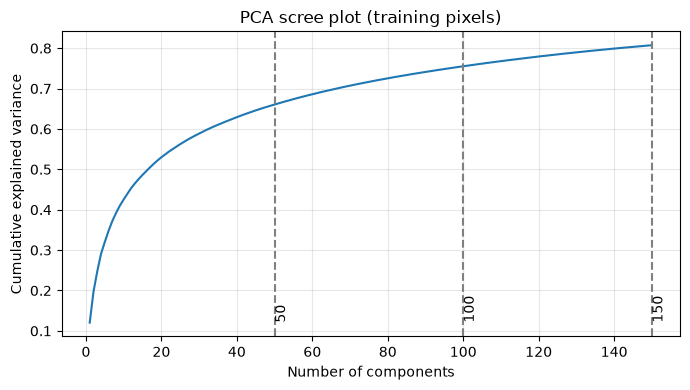

In [ ]:
# Scree plot: cumulative explained variance (up to 600 components)
pca_full = PCA(600, random_state=42).fit(Xp_tr)
cum = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum) + 1), cum)
for n in N_COMPONENTS:
    plt.axvline(n, ls='--', c='grey', lw=.8)
for thr in [0.90, 0.95]:
    plt.axhline(thr, ls=':', c='red', lw=.8)
    if cum[-1] >= thr:
        print(f'{int(thr*100)}% of the variance needs {int(np.searchsorted(cum, thr) + 1)} components')
    else:
        print(f'{int(thr*100)}% of the variance is not reached within 600 components')
plt.xlabel('Number of components'); plt.ylabel('Cumulative explained variance')
plt.title('PCA scree plot (training pixels)'); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f'{RESULTS}/eda_visualizations/pca_scree.png', dpi=200); plt.show()

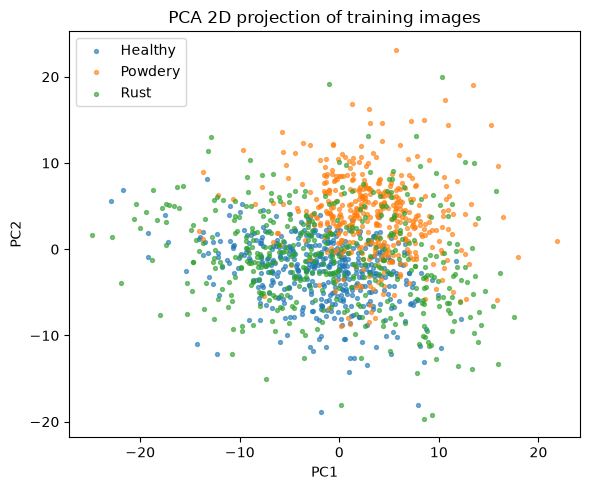

In [12]:
# First two principal components, coloured by true class
Z = PCA(2, random_state=42).fit_transform(Xp_tr)
plt.figure(figsize=(6, 5))
for i, c in enumerate(CLASS_NAMES):
    plt.scatter(Z[y_tr == i, 0], Z[y_tr == i, 1], s=8, alpha=.6, label=c)
plt.legend(); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('PCA 2D projection of training images')
plt.tight_layout(); plt.savefig(f'{RESULTS}/eda_visualizations/pca_2d_scatter.png', dpi=200); plt.show()

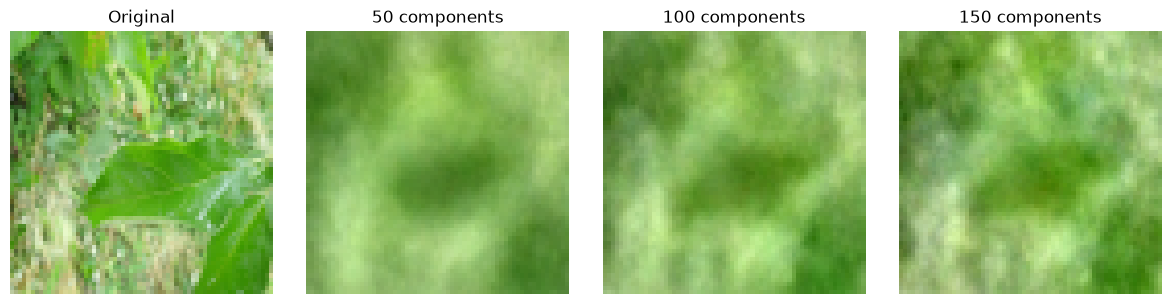

In [13]:
# Reconstruction: original vs image rebuilt from n components
sample = Xp_tr[0:1]
fig, ax = plt.subplots(1, len(N_COMPONENTS) + 1, figsize=(3 * (len(N_COMPONENTS) + 1), 3))
ax[0].imshow(sample.reshape(64, 64, 3)); ax[0].set_title('Original'); ax[0].axis('off')
for a, n in zip(ax[1:], N_COMPONENTS):
    p = pipes[n].named_steps['pca']
    rec = p.inverse_transform(p.transform(sample)).reshape(64, 64, 3).clip(0, 1)
    a.imshow(rec); a.set_title(f'{n} components'); a.axis('off')
plt.tight_layout(); plt.savefig(f'{RESULTS}/eda_visualizations/pca_reconstruction.png', dpi=200); plt.show()

In [ ]:
# Choose the best PCA setting by cross-validation accuracy (not by test accuracy)
pca_rows = comparison[comparison['Variety'] != 'No PCA']
best = pca_rows.sort_values('CV acc (Train)', ascending=False).iloc[0]
print('Selected:', best['Variety'], '| components =', int(best['Features']), '| CV acc =', best['CV acc (Train)'])
for _, r in comparison.iterrows():
    log_result('PCA + SVM check', r['Variety'], r['Val acc'], r['Test acc'], f"variance={r['Variance retained']}")

Selected n_components = 150


## Comparison across varieties

| Variety | Features | Variance retained | CV acc | Val acc | Test acc | Test macro-F1 | Fit time (s) |
|---|---|---|---|---|---|---|---|
| No PCA | 12,288 | 1.000 | not run | 0.700 | 0.747 | 0.745 | 263.5 |
| PCA 50 | 50 | 0.660 | 0.812 | 0.767 | 0.647 | 0.646 | 0.8 |
| PCA 100 | 100 | 0.755 | 0.817 | 0.750 | 0.673 | 0.671 | 2.6 |
| PCA 150 | 150 | 0.807 | 0.826 | 0.800 | 0.707 | 0.706 | 1.8 |

- **Number of components:** Variance retained rises from 66.0% (50) to 75.5% (100) to 80.7% (150). Test accuracy rises in step with it, from 0.647 to 0.673 to 0.707, so more components helped throughout the range tried.
- **Speed:** The no-PCA SVM took about 263 s to fit, compared with under 3 s for any PCA variety. With 150 components that is roughly 150 times faster.
- **Accuracy cost:** No PCA still has the highest Test accuracy (0.747), about 4 points above PCA 150. PCA trades a small accuracy loss for a very large speed-up.
- **CV for no PCA:** 5-fold cross-validation was not run for the no-PCA model because a single fit takes over four minutes.

## Conclusion

I selected **PCA with 150 components** because it had the highest 5-fold CV accuracy on the training set (0.826), not the highest test accuracy.
It keeps 80.7% of the variance with 150 features instead of 12,288, and fits about 150 times faster than the no-PCA SVM, at a cost of about 4 points of Test accuracy (0.707 vs 0.747).
PCA is unsupervised, so I judged it by the variance retained and by the accuracy and macro-F1 of a downstream SVM (Test macro-F1 0.706).

The CV accuracy (0.826) is higher than the Test accuracy (0.707). Possible reasons are that the Test set is small (150 images, so one image is 0.7%),
and that similar photos inside the Train folder can make cross-validation look optimistic. I have not tested these explanations.

Overall, pixel PCA is useful here for speed and compression, but it does not beat the no-PCA model, and it is far weaker than colour-histogram features
(the SVM and Random Forest models reached 0.81–0.90 test accuracy on histogram features).

## Limitations
PCA is linear, so it cannot capture non-linear structure in leaf texture, and it works on raw pixels, so it ignores spatial layout.
Only 50, 100 and 150 components were tried, and variance was still rising at 150, so a larger number might do better.
Possible improvements: try 200+ components, Kernel PCA, or PCA on colour-histogram plus texture features.